# 03 · Analyse exploratoire et corrélations

**Questions du commanditaire**
1. Quelles régions sont les plus touchées par la sous-nutrition ?
2. Quelles disparités de disponibilité alimentaire entre pays ?
3. La disponibilité alimentaire est-elle liée à la sous-nutrition ? Et la composition du régime ? La taille du pays ?

**Périmètre.** Les tests portant sur le taux de sous-nutrition utilisent les **96 zones où il est mesuré**.
Les 78 autres (borne « <0,1 million », NR, NV) ne sont pas des absences au hasard (notebook 01) :
les inclure avec une valeur inventée biaiserait les résultats. Elles seront imputées au notebook 04.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RACINE / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RACINE / "data" / "global_fao_dataset.csv")
mesure = df.dropna(subset=["Taux_sous_nutrition_pct"]).copy()
print(f"{len(df)} zones, dont {len(mesure)} avec un taux de sous-nutrition mesuré")

174 zones, dont 96 avec un taux de sous-nutrition mesuré


## 1. Analyse univariée

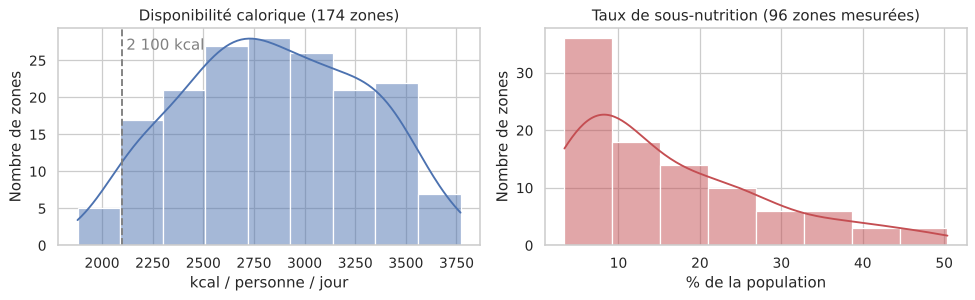

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["Kcal_total"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(2100, ls="--", c="grey"); axes[0].text(2120, axes[0].get_ylim()[1] * 0.9, "2 100 kcal", color="grey")
axes[0].set(title="Disponibilité calorique (174 zones)", xlabel="kcal / personne / jour", ylabel="Nombre de zones")
sns.histplot(mesure["Taux_sous_nutrition_pct"], kde=True, ax=axes[1], color="#C44E52")
axes[1].set(title="Taux de sous-nutrition (96 zones mesurées)", xlabel="% de la population", ylabel="Nombre de zones")
plt.tight_layout(); fig.savefig(FIG / "distributions.png", dpi=120)

In [3]:
for col, d in [("Kcal_total", df), ("Taux_sous_nutrition_pct", mesure)]:
    w, p = stats.shapiro(d[col])
    print(f"{col:25s} médiane = {d[col].median():7.1f}   asymétrie = {d[col].skew():5.2f}   Shapiro-Wilk p = {p:.4f}")

Kcal_total                médiane =  2830.5   asymétrie = -0.01   Shapiro-Wilk p = 0.0294
Taux_sous_nutrition_pct   médiane =    12.2   asymétrie =  1.05   Shapiro-Wilk p = 0.0000


**Lecture.** La disponibilité calorique est presque symétrique (asymétrie ≈ 0), même si le test de
Shapiro-Wilk rejette de peu la normalité (p ≈ 0,03). Le taux de sous-nutrition est **fortement asymétrique** :
la plupart des pays mesurés sont sous 15 %, une minorité dépasse 30 %, et la normalité est nettement rejetée.
Pour les corrélations impliquant ce taux, on utilisera donc **Spearman** (corrélation de rang, sans
hypothèse de normalité), en donnant Pearson pour information.

## 2. Pays et régions les plus touchés

In [4]:
cols = ["Zone", "Region", "Taux_sous_nutrition_pct", "Sous_alimentation_millions", "Kcal_total"]
top10 = mesure.nlargest(10, "Taux_sous_nutrition_pct")[cols]
top10

,Zone,Region,Taux_sous_nutrition_pct,Sous_alimentation_millions,Kcal_total
70,Haïti,Amérique latine et Caraïbes,50.40,5.20,2 089.00
172,Zambie,Afrique subsaharienne,48.15,7.00,1 924.00
173,Zimbabwe,Afrique subsaharienne,46.64,6.60,2 113.00
131,République centrafricaine,Afrique subsaharienne,43.33,2.00,1 879.00
136,République populaire démocratique de Corée,Asie de l'Est et du Sud-Est,42.58,10.60,2 093.00
39,Congo,Afrique subsaharienne,40.47,1.80,2 206.00
157,Tchad,Afrique subsaharienne,38.21,4.90,2 109.00
5,Angola,Afrique subsaharienne,37.72,8.10,2 474.00
93,Libéria,Afrique subsaharienne,37.26,1.60,2 206.00
97,Madagascar,Afrique subsaharienne,35.77,8.20,2 056.00


In [5]:
regions = (mesure.groupby("Region")
           .agg(zones_mesurees=("Zone", "size"),
                taux_median_pct=("Taux_sous_nutrition_pct", "median"),
                personnes_sous_alimentees_M=("Sous_alimentation_millions", "sum"))
           .join(df.groupby("Region").agg(zones=("Zone", "size"), kcal_mediane=("Kcal_total", "median")))
           .sort_values("taux_median_pct", ascending=False))
regions["part_du_total_pct"] = regions["personnes_sous_alimentees_M"] / regions["personnes_sous_alimentees_M"].sum() * 100
regions.round(1)

,zones_mesurees,taux_median_pct,personnes_sous_alimentees_M,zones,kcal_mediane,part_du_total_pct
Region,,,,,,
Afrique subsaharienne,37,23.10,159.30,40,2 424.50,21.40
Asie de l'Est et du Sud-Est,13,12.40,213.20,18,2 761.50,28.70
Amérique latine et Caraïbes,18,10.60,33.60,33,2 731.00,4.50
Asie centrale et du Sud,10,9.90,300.20,13,2 672.00,40.40
Afrique du Nord et Asie de l'Ouest,14,5.50,36.10,19,3 140.00,4.90
Europe et Amérique du Nord,4,5.40,1.30,42,3 363.00,0.20


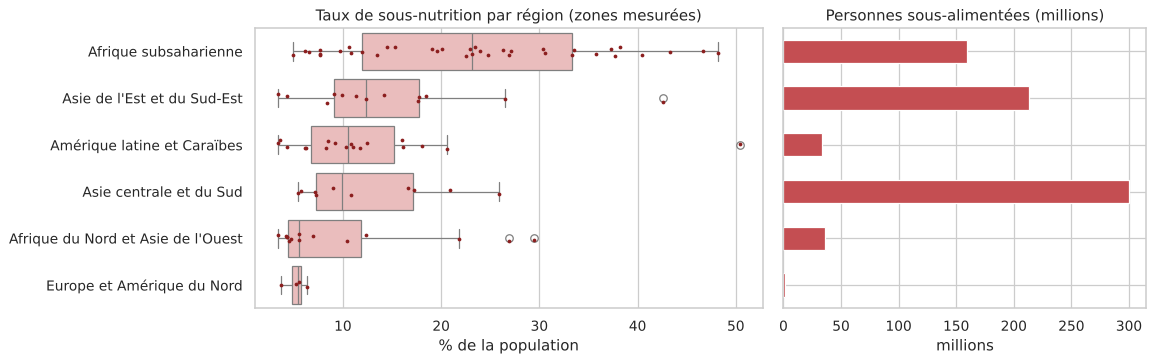

In [6]:
ordre = regions.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.boxplot(data=mesure, y="Region", x="Taux_sous_nutrition_pct", order=ordre, ax=axes[0], color="#F2B5B5")
sns.stripplot(data=mesure, y="Region", x="Taux_sous_nutrition_pct", order=ordre, ax=axes[0], color="#8B1E1E", size=3)
axes[0].set(title="Taux de sous-nutrition par région (zones mesurées)", xlabel="% de la population", ylabel="")
regions["personnes_sous_alimentees_M"].loc[ordre].plot.barh(ax=axes[1], color="#C44E52")
axes[1].invert_yaxis(); axes[1].set(title="Personnes sous-alimentées (millions)", xlabel="millions", ylabel=""); axes[1].set_yticklabels([])
plt.tight_layout(); fig.savefig(FIG / "regions.png", dpi=120)

**Lecture.**

- **En taux**, l'Afrique subsaharienne est de loin la plus touchée : médiane ≈ 23 %, contre 5 à 12 % ailleurs.
- **En nombre de personnes**, l'Asie centrale et du Sud (Inde, Pakistan, Bangladesh) et l'Asie de l'Est et du
  Sud-Est (Chine, Indonésie, Philippines) concentrent plus des deux tiers des 744 millions de personnes
  sous-alimentées mesurées : taux plus bas, mais populations immenses.
- Les deux lectures sont nécessaires : un programme ciblé sur les taux ne choisira pas les mêmes pays qu'un
  programme ciblé sur le nombre de personnes.
- L'Océanie n'a aucun taux mesuré (uniquement des bornes « <0,1 million ») et l'Europe / Amérique du Nord
  n'en a que 4 : leurs boîtes ne sont pas représentatives.

## 3. Cartographie

In [7]:
import plotly.express as px

fig = px.choropleth(
    mesure, locations="ISO3", color="Taux_sous_nutrition_pct", hover_name="Zone",
    color_continuous_scale="Reds", range_color=(0, 50),
    labels={"Taux_sous_nutrition_pct": "Sous-nutrition (%)"},
    title="Taux de sous-nutrition 2012-2014 (zones mesurées ; en gris : non mesuré)",
)
fig.show()

<Figure plotly>

*La carte est interactive (survol = nom du pays et taux). Elle s'affiche dans VS Code / Jupyter avec `plotly` installé.*

## 4. Corrélations

Seuil de significativité retenu : **α = 0,05**. Pour chaque test : hypothèse, vérification des conditions,
résultat chiffré avec la taille d'échantillon, et lecture métier.

### 4.1 Disponibilité calorique × taux de sous-nutrition (quantitatif × quantitatif)

H₀ : pas de relation monotone entre les deux variables.

Spearman ρ = -0.89 (p = 2.1e-34) | pour information Pearson r = -0.83 | n = 96


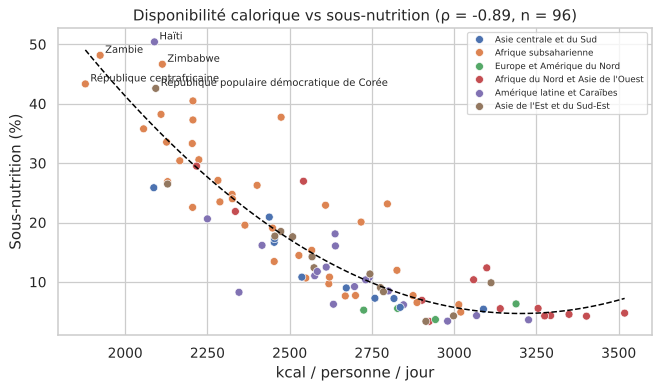

In [8]:
def spearman(x, y, data):
    d = data[[x, y]].dropna()
    rho, p = stats.spearmanr(d[x], d[y])
    r, p_r = stats.pearsonr(d[x], d[y])
    print(f"Spearman ρ = {rho:.2f} (p = {p:.1e}) | pour information Pearson r = {r:.2f} | n = {len(d)}")
    return rho, p

rho_kcal, p_kcal = spearman("Kcal_total", "Taux_sous_nutrition_pct", mesure)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.scatterplot(data=mesure, x="Kcal_total", y="Taux_sous_nutrition_pct", hue="Region", ax=ax, s=40)
sns.regplot(data=mesure, x="Kcal_total", y="Taux_sous_nutrition_pct", scatter=False, order=2, ci=None, ax=ax, color="black",
            line_kws={"lw": 1.2, "ls": "--"})
for _, r in mesure.nlargest(5, "Taux_sous_nutrition_pct").iterrows():
    ax.annotate(r["Zone"], (r["Kcal_total"], r["Taux_sous_nutrition_pct"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set(title=f"Disponibilité calorique vs sous-nutrition (ρ = {rho_kcal:.2f}, n = {len(mesure)})",
       xlabel="kcal / personne / jour", ylabel="Sous-nutrition (%)")
ax.legend(fontsize=7, title=None)
plt.tight_layout(); fig.savefig(FIG / "kcal_vs_sous_nutrition.png", dpi=120)

**Lecture métier.** Relation **négative, forte et significative** : plus la disponibilité calorique d'un pays
est élevée, plus son taux de sous-nutrition est faible. La courbe de tendance (polynôme de degré 2, en pointillés) montre une relation non linéaire : la
sous-nutrition chute vite entre 1 900 et 2 600 kcal, puis plafonne sous 10 % au-delà de 3 000 kcal.
C'est une **association**, pas une preuve de cause : la disponibilité moyenne ne dit rien de la répartition
au sein d'un pays (prix, revenus, conflits).

### 4.2 Part des protéines animales × taux de sous-nutrition (quantitatif × quantitatif)

H₀ : pas de relation monotone. La part animale (normalité rejetée) mesure la diversité du régime.

Spearman ρ = -0.53 (p = 3.9e-08) | pour information Pearson r = -0.48 | n = 96
Spearman ρ = 0.17 (p = 9.1e-02) | pour information Pearson r = 0.07 | n = 96


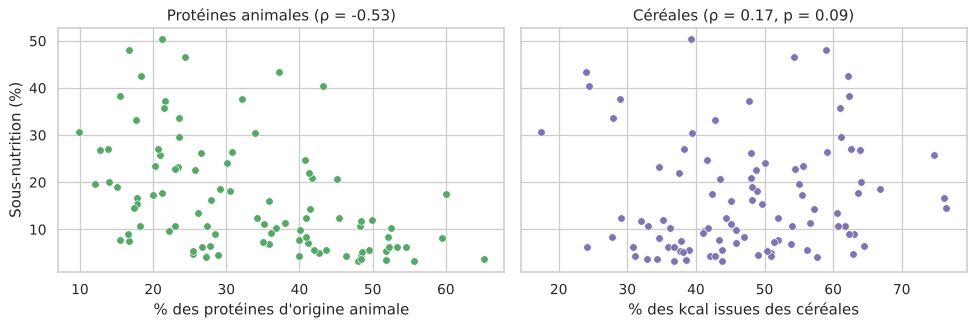

In [9]:
rho_prot, p_prot = spearman("Part_prot_animal_pct", "Taux_sous_nutrition_pct", mesure)
rho_cer, p_cer = spearman("Part_kcal_cereales_pct", "Taux_sous_nutrition_pct", mesure)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
sns.scatterplot(data=mesure, x="Part_prot_animal_pct", y="Taux_sous_nutrition_pct", ax=axes[0], color="#55A868")
axes[0].set(title=f"Protéines animales (ρ = {rho_prot:.2f})", xlabel="% des protéines d'origine animale", ylabel="Sous-nutrition (%)")
sns.scatterplot(data=mesure, x="Part_kcal_cereales_pct", y="Taux_sous_nutrition_pct", ax=axes[1], color="#8172B2")
axes[1].set(title=f"Céréales (ρ = {rho_cer:.2f}, p = {p_cer:.2f})", xlabel="% des kcal issues des céréales")
plt.tight_layout(); fig.savefig(FIG / "regime_vs_sous_nutrition.png", dpi=120)

**Lecture métier.**

- **Protéines animales** : corrélation négative, modérée et significative. Les pays où la sous-nutrition
  est forte ont un régime peu diversifié, très majoritairement végétal.
- **Céréales** : pas de corrélation significative au seuil de 5 %. Dépendre des céréales ne dit pas à lui seul
  si un pays souffre de sous-nutrition (le Maghreb est très céréalier, mais peu touché).

### 4.3 Population × disponibilité calorique (quantitatif × quantitatif)

H₀ : la taille d'un pays n'est pas liée à la disponibilité par habitant. Population très asymétrique
(de 54 000 à 1,4 milliard) : Spearman, sur les 174 zones.

In [10]:
rho_pop, p_pop = spearman("Population_millions", "Kcal_total", df)

Spearman ρ = 0.05 (p = 5.0e-01) | pour information Pearson r = 0.02 | n = 174


**Lecture métier.** Pas de relation significative (p > 0,05) : un pays peuplé n'est ni mieux ni moins bien
approvisionné par habitant. La sous-nutrition n'est pas une question de taille démographique.

### 4.4 Région × taux de sous-nutrition (qualitatif × quantitatif)

H₀ : la distribution du taux est la même dans toutes les régions. Océanie exclue (aucune valeur mesurée).
On vérifie la normalité dans chaque groupe et l'homogénéité des variances avant de choisir entre ANOVA
et Kruskal-Wallis.

In [11]:
groupes = {reg: g["Taux_sous_nutrition_pct"].values for reg, g in mesure.groupby("Region") if len(g) >= 3}
for reg, v in groupes.items():
    print(f"{reg:36s} n = {len(v):2d}   Shapiro p = {stats.shapiro(v).pvalue:.3f}")
lev = stats.levene(*groupes.values())
kw = stats.kruskal(*groupes.values())
n = sum(len(v) for v in groupes.values())
eps2 = (kw.statistic - len(groupes) + 1) / (n - len(groupes))
print(f"\nLevene p = {lev.pvalue:.3f}")
print(f"Kruskal-Wallis H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}, n = {n}, taille d'effet ε² = {eps2:.2f}")

Afrique du Nord et Asie de l'Ouest   n = 14   Shapiro p = 0.001
Afrique subsaharienne                n = 37   Shapiro p = 0.136
Amérique latine et Caraïbes          n = 18   Shapiro p = 0.000
Asie centrale et du Sud              n = 10   Shapiro p = 0.156
Asie de l'Est et du Sud-Est          n = 13   Shapiro p = 0.035
Europe et Amérique du Nord           n =  4   Shapiro p = 0.640

Levene p = 0.078
Kruskal-Wallis H = 27.0, p = 5.6e-05, n = 96, taille d'effet ε² = 0.24


**Choix du test.** La normalité est rejetée dans au moins un groupe : l'ANOVA n'est pas adaptée, on
retient **Kruskal-Wallis**. **Lecture** : la région est significativement liée au taux de sous-nutrition,
avec un effet important. C'est cohérent avec le §2 : l'Afrique subsaharienne se détache nettement.

## 5. Synthèse pour le commanditaire

| Question | Test | Résultat | Lecture |
|---|---|---|---|
| Calories × sous-nutrition | Spearman, n = 96 | ρ ≈ −0,89, p < 0,001 | lien négatif fort |
| Protéines animales × sous-nutrition | Spearman, n = 96 | ρ ≈ −0,53, p < 0,001 | lien négatif modéré |
| Céréales × sous-nutrition | Spearman, n = 96 | ρ ≈ 0,17, p ≈ 0,09 | pas de lien significatif |
| Population × calories | Spearman, n = 174 | ρ ≈ 0,05, p ≈ 0,50 | pas de lien |
| Région × sous-nutrition | Kruskal-Wallis, n = 96 | p < 0,001 | l'Afrique subsaharienne se détache |

1. **Priorité géographique** : l'Afrique subsaharienne en taux, l'Asie du Sud et du Sud-Est en nombre de personnes.
2. **Levier** : la disponibilité calorique est le signal le plus fortement associé à la sous-nutrition ;
   la diversité du régime (part animale) vient ensuite.
3. **Limite** : 78 zones sans taux mesuré, surtout des pays riches ; un indicateur moyen par pays masque les
   inégalités internes.